In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded= files.upload()

Saving weather data classification - weather data classification.csv to weather data classification - weather data classification.csv


In [ ]:
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

In [ ]:
df.head(5)

,Wind Speed,Precipitation (%),Cloud Cover,Atmospheric Pressure,UV Index,Season,Visibility (km),Location,"{Temperature},{Humdity}",Weather Type
0,0.002638888888888889KM/S,82,partly cloudy,1010.82,2,Wentar,3.5,inland,"{""Temperature"": {""value"": 14.0, ""unit"": ""C""}, ...",Rainy
1,8.5,71,partly CLOUDY,1011.43,7,Spring,10.0,inland,"{""Temperature"": {""value"": 39.0, ""unit"": ""C""}, ...",Cloudy
2,7,16,clear,1018.72,5,Spring,5.5,mountain,"{""Temperature"": {""value"": 30.0, ""unit"": ""C""}, ...",Sunny
3,1.5,82,clear,1026.25,7,Spring,1.0,coastal,"{""Temperature"": {""value"": 38.0, ""unit"": ""C""}, ...",Sunny
4,17,66,overcast,990.67,1,Winter,2.5,mountain,"{""Temperature"": {""value"": 27.0, ""unit"": ""C""}, ...",Rainy


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13200 entries, 0 to 13199
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Wind Speed               13200 non-null  object 
 1   Precipitation (%)        13200 non-null  object 
 2   Cloud Cover              13200 non-null  object 
 3   Atmospheric Pressure     13200 non-null  float64
 4   UV Index                 13200 non-null  int64  
 5   Season                   13200 non-null  object 
 6   Visibility (km)          13200 non-null  float64
 7   Location                 13200 non-null  object 
 8   {Temperature},{Humdity}  13200 non-null  object 
 9   Weather Type             13200 non-null  object 
dtypes: float64(2), int64(1), object(7)
memory usage: 1.0+ MB


In [ ]:
df.describe()

,Atmospheric Pressure,UV Index,Visibility (km)
count,13200.000000,13200.000000,13200.000000
mean,1005.827896,4.005758,5.462917
std,37.199589,3.856600,3.371499
min,800.120000,0.000000,0.000000
25%,994.800000,1.000000,3.000000
50%,1007.650000,3.000000,5.000000
75%,1016.772500,7.000000,7.500000
max,1199.210000,14.000000,20.000000


In [ ]:
df.isnull().sum()

,0
Wind Speed,0
Precipitation (%),0
Cloud Cover,0
Atmospheric Pressure,0
UV Index,0
Season,0
Visibility (km),0
Location,0
"{Temperature},{Humdity}",0
Weather Type,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.columns

Index(['Wind Speed', 'Precipitation (%)', 'Cloud Cover',
       'Atmospheric Pressure', 'UV Index', 'Season', 'Visibility (km)',
       'Location', '{Temperature},{Humdity}', 'Weather Type'],
      dtype='object')

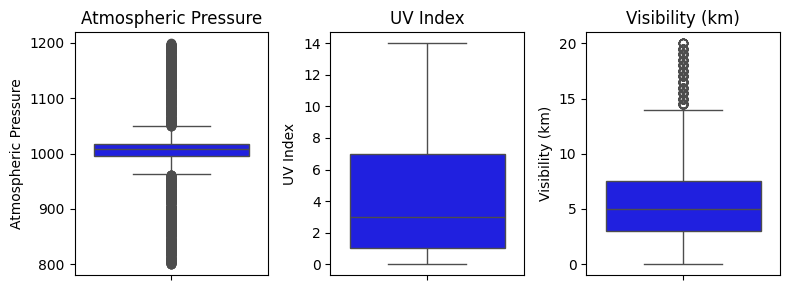

In [ ]:
numeric_cols = ['Atmospheric Pressure', 'UV Index', 'Visibility (km)']

import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,3, figsize=(8,3))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i], color='blue')
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

In [ ]:
df.shape

(12011, 10)

In [ ]:

num_cols = df.select_dtypes(include=['int64', 'float64']).columns


for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df = df[(df[col] >= lower) & (df[col] <= upper)]

print("Shape after outlier removal:", df.shape)


Shape after outlier removal: (12011, 10)


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn import tree

In [ ]:
cat_cols = df.select_dtypes(include='object').columns.drop('Weather Type')

df = pd.get_dummies(
    df,
    columns=cat_cols,
    drop_first=True
)


In [ ]:
X = df.drop('Weather Type', axis=1)
y = df['Weather Type']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
model = DecisionTreeClassifier(
    criterion='gini',
    max_depth=5,
    random_state=42
)



In [ ]:
model.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=5, random_state=42)

In [ ]:
y_pred = model.predict(X_test)

In [ ]:

print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9216216216216216


In [ ]:
model_two = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=4,
    random_state=42
)


In [ ]:
model_two.fit(X_train, y_train)


DecisionTreeClassifier(criterion='entropy', max_depth=4, random_state=42)

In [ ]:
y_pred = model_two.predict(X_test)

In [ ]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.8972972972972973


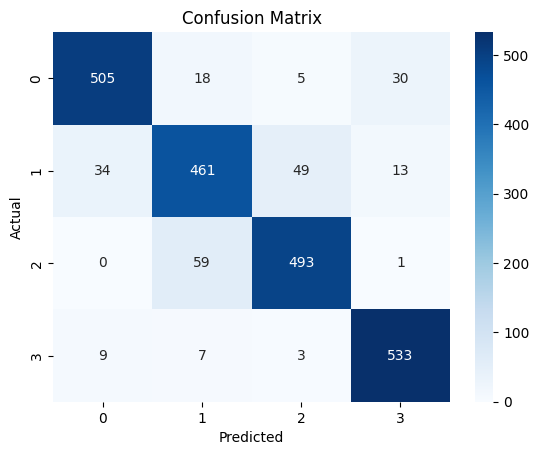

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

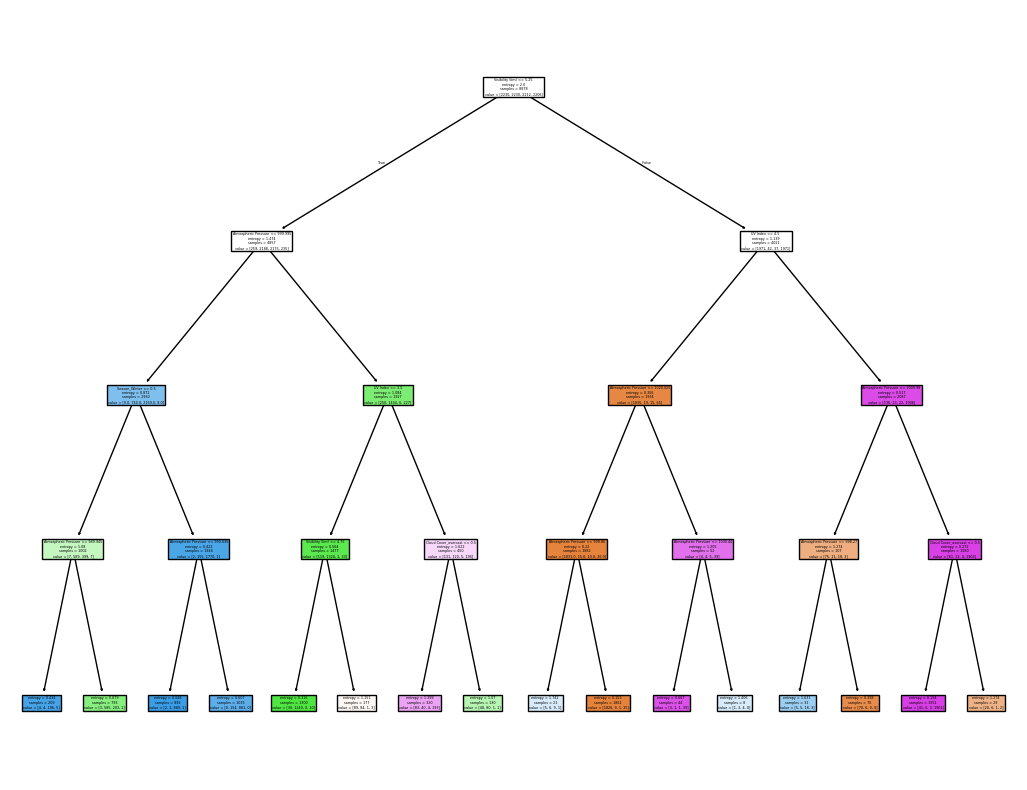

In [ ]:
plt.figure(figsize=(13, 10))

tree.plot_tree(
    model_two,
    feature_names=X.columns.tolist(),
    filled=True
)

plt.show()